# Stability Margin Visualization
This notebook visualizes per-step stability margins and per-leg test margins from a single CSV.

In [26]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
import random

# CSV_PATH = Path('data/stability_margin/signed_stability_margin_20260116_164524.csv') # Asymmetry test example
# CSV_PATH = Path('data/stability_margin/signed_stability_margin_20260116_163645.csv') #symmetry test
CSV_PATH = Path('data/stability_margin/signed_stability_margin_20260121_101906.csv')
df = pd.read_csv(CSV_PATH)
df.head()


,sample_index,step_index,angle_0,angle_1,angle_2,angle_3,angle_4,angle_5,support_margin,lifted_legs,min_step_support_margin,mean_step_support_margin,leg_test_margin_0,leg_test_margin_1,leg_test_margin_2,leg_test_margin_3,leg_test_margin_4,leg_test_margin_5,roll_angle,pitch_angle
0,0,0,110,163,189,215,294,326,0.309017,NaN,-0.147809,0.299271,-0.147809,0.309017,0.309017,0.309017,0.309017,0.034899,1.649263e-14,-89.999986
1,0,1,110,163,189,215,294,326,0.309017,1.0,-0.147809,0.299271,-0.147809,0.309017,0.309017,0.309017,0.309017,0.034899,-8.849329e+01,-88.249544
2,0,2,110,163,189,215,294,326,0.309017,1.0,-0.147809,0.299271,-0.147809,0.309017,0.309017,0.309017,0.309017,0.034899,-8.874616e+01,-84.678758
3,0,3,110,163,189,215,294,326,0.309017,1.0,-0.147809,0.299271,-0.147809,0.309017,0.309017,0.309017,0.309017,0.034899,-8.906240e+01,-81.071271
4,0,4,110,163,189,215,294,326,0.309017,1.0,-0.147809,0.299271,-0.147809,0.309017,0.309017,0.309017,0.309017,0.034899,-8.935383e+01,-77.516159


In [103]:
def asymmetry_index(angles):
    angles = [a % 360 for a in angles]
    angles.sort()
    gaps = [angles[i + 1] - angles[i] for i in range(len(angles) - 1)]
    gaps.append(angles[0] + 360 - angles[-1])
    mean_gap = np.mean(gaps)
    std_gap = np.std(gaps, ddof=0)
    result = std_gap / mean_gap if mean_gap else 0.0
    return result


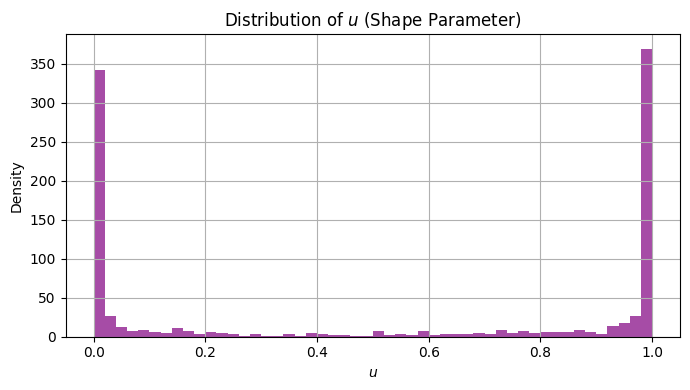

You can tune parameters such as 'jitter_deg', 'min_angle', or the sampling method to change the shape of the distribution of u.


In [207]:
import numpy as np

rng = np.random.default_rng(0)

# U-shaped in [0, 1]
u = rng.beta(0.1, 0.1, size=1000)


plt.figure(figsize=(7, 4))
plt.hist(u, bins=50, density=False, alpha=0.7, color='purple')
plt.title('Distribution of $u$ (Shape Parameter)')
plt.xlabel('$u$')
plt.ylabel('Density')
plt.grid(True)
plt.tight_layout()
plt.show()

# The shape of the distribution of u can be tuned by changing the parameters
# that control how u is generated. For example, if u is derived from jitter or jitter_deg,
# you can adjust 'jitter_deg', 'min_angle', or the way 'centers' are defined.
# If u is a function of random sampling, changing the noise or constraints will affect the shape.
print("You can tune parameters such as 'jitter_deg', 'min_angle', or the sampling method to change the shape of the distribution of u.")

In [202]:
import random

def generate_random_angles(
    num_leg,
    angle_min=0,
    angle_max=360,
    min_diff=25,
    max_attempts=1000,
    centers=[0, 60, 120, 180, 240, 300],
    dis='gaussian',
    jitter_deg=0.0,
): 
    """
    Generate random angles for num_leg legs. If centers is provided, sample around
    those angles with Gaussian noise (jitter_deg) and wrap to [0, 360).
    Otherwise sample uniformly between angle_min and angle_max.
    """
    if centers is not None:
        if len(centers) != num_leg:
            raise ValueError("centers length must match num_leg")
        centers = [c % 360 for c in centers]

    for _ in range(max_attempts):
        if dis == "uniform":
            angles = [int(round(random.uniform(angle_min, angle_max))) for _ in range(num_leg)]
        elif dis == "gaussian":
            # Sample each angle from a normal distribution centered at mean of angle_min and angle_max
            # Sample each angle from a normal distribution centered at each center
            angles = []
            for c in centers:
                angle = np.random.normal(loc=c, scale=jitter_deg)
                angle = int(round(angle)) % 360
                angles.append(angle)
        elif dis == "u-shaped":
            # Sample from U-shaped distribution and center around each ideal angle
            angles = []
            for c in centers:
                # u is in [0, 1], map to [-jitter_deg, +jitter_deg]
                u_val = rng.beta(1.0, 1.0)
                jitter = u_val* jitter_deg * (1 if random.random() < 0.5 else -1)
                angle = (c + jitter) % 360
                angles.append(int(round(angle)))
        print("Generated angles: ", angles)
        angles = sorted(angles)
        valid = True
        for i in range(num_leg):
            a1 = angles[i]
            a2 = angles[(i + 1) % num_leg]
            diff = abs(a2 - a1)
            if diff > 180:
                diff = 360 - diff
            if diff < min_diff:
                valid = False
                break
        if valid:
            print("Attempt: ", _)
            return angles
    raise ValueError(f"Could not generate valid angles after {max_attempts} attempts.")


Generated angles:  [3, 98, 102, 130, 298, 225]
Generated angles:  [327, 29, 188, 238, 200, 250]
Generated angles:  [86, 81, 126, 248, 255, 218]
Generated angles:  [281, 71, 186, 155, 154, 348]
Generated angles:  [308, 143, 88, 96, 271, 246]
Generated angles:  [344, 350, 130, 264, 216, 263]
Generated angles:  [64, 343, 82, 136, 254, 4]
Generated angles:  [274, 80, 74, 146, 301, 242]
Generated angles:  [291, 360, 158, 122, 302, 248]
Generated angles:  [27, 341, 47, 193, 208, 277]
Generated angles:  [349, 80, 84, 115, 301, 316]
Generated angles:  [83, 85, 122, 245, 255, 27]
Generated angles:  [334, 107, 80, 249, 214, 22]
Attempt:  12
Generated angles:  [57, 60, 161, 177, 269, 337]
Generated angles:  [329, 131, 151, 258, 269, 7]
Generated angles:  [84, 46, 170, 126, 152, 20]
Generated angles:  [300, 98, 99, 131, 275, 29]
Generated angles:  [76, 15, 87, 138, 188, 214]
Generated angles:  [68, 9, 56, 196, 156, 257]
Generated angles:  [350, 334, 92, 159, 241, 333]
Generated angles:  [31, 31, 2

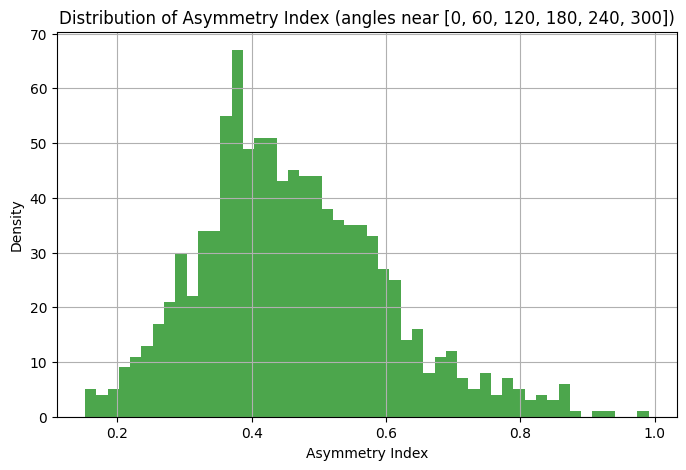

In [203]:
num_samples = 1000
min_angle = 25
num_legs = 6
centers = [0, 60, 120, 180, 240, 300]
jitter_deg = 90
samples = [
    generate_random_angles(
        num_legs,
        min_diff=min_angle,
        centers=centers,
        jitter_deg=jitter_deg,
        dis='u-shaped', # 'uniform' or 'u-shaped', 'gaussian'
    )
    for _ in range(num_samples)
]
asym_indices = [asymmetry_index(sample) for sample in samples]

plt.figure(figsize=(8, 5))
plt.hist(asym_indices, bins=50, density=False, alpha=0.7, color='green')
plt.title('Distribution of Asymmetry Index (angles near [0, 60, 120, 180, 240, 300])')
plt.xlabel('Asymmetry Index')
plt.ylabel('Density')
plt.grid(True)
plt.show()


In [111]:
import numpy as np

angle_cols = [f'angle_{i}' for i in range(6)]
unique_angles = df[angle_cols].drop_duplicates().reset_index(drop=True)
unique_angles.insert(0, 'morphology_id', unique_angles.index + 1)
unique_angles['asymmetry_index'] = unique_angles.iloc[:, 1:].apply(lambda r: asymmetry_index(r.tolist()), axis=1)
print("Unique angle configurations:", unique_angles)
unique_angles



Unique angle configurations:     morphology_id  angle_0  angle_1  angle_2  angle_3  angle_4  angle_5  \
0               1      110      163      189      215      294      326   
1               2       95      123      171      270      305      350   
2               3       74      110      191      229      256      348   
3               4       60      149      207      253      301      338   
4               5       55      109      136      232      283      319   
..            ...      ...      ...      ...      ...      ...      ...   
95             96       47      112      149      187      298      342   
96             97       84      136      184      231      259      320   
97             98       44       90      184      226      327      354   
98             99       18       92      123      231      288      340   
99            100       17       63      108      136      188      293   

    asymmetry_index  
0          0.699272  
1          0.507536  
2   

,morphology_id,angle_0,angle_1,angle_2,angle_3,angle_4,angle_5,asymmetry_index
0,1,110,163,189,215,294,326,0.699272
1,2,95,123,171,270,305,350,0.507536
2,3,74,110,191,229,256,348,0.445658
3,4,60,149,207,253,301,338,0.318997
4,5,55,109,136,232,283,319,0.450000
...,...,...,...,...,...,...,...,...
95,96,47,112,149,187,298,342,0.426006
96,97,84,136,184,231,259,320,0.504517
97,98,44,90,184,226,327,354,0.458762
98,99,18,92,123,231,288,340,0.424809


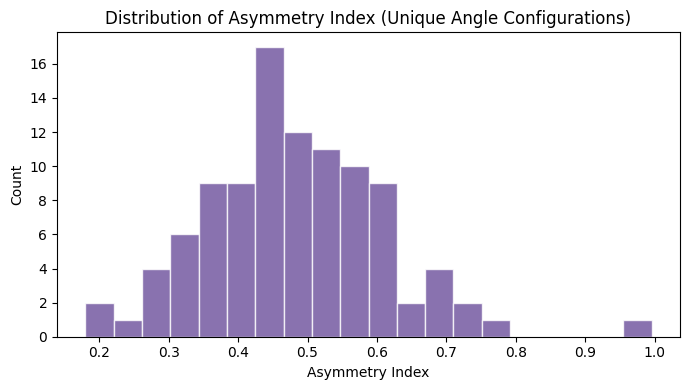

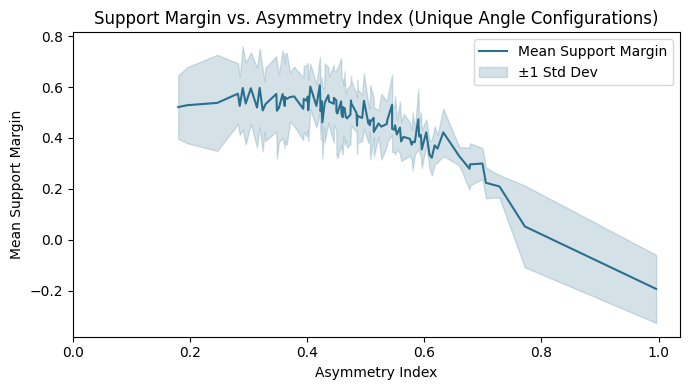

In [170]:
plt.figure(figsize=(7, 4))
plt.hist(unique_angles['asymmetry_index'], bins=20, color='#6C4F9B', edgecolor='white', alpha=0.8)
plt.title('Distribution of Asymmetry Index (Unique Angle Configurations)')
plt.xlabel('Asymmetry Index')
plt.ylabel('Count')
plt.tight_layout()
plt.show()

# Compute mean and std of support_margin for each unique asymmetry_index
grouped = df.groupby(angle_cols)['support_margin'].agg(['mean', 'std']).reset_index()
# Merge with unique_angles to get asymmetry_index
merged = pd.merge(unique_angles, grouped, on=angle_cols)

# Sort by asymmetry_index for line plot
merged_sorted = merged.sort_values('asymmetry_index')

plt.figure(figsize=(7, 4))
plt.plot(merged_sorted['asymmetry_index'], merged_sorted['mean'], color='#2A6F8E', label='Mean Support Margin')
plt.fill_between(
    merged_sorted['asymmetry_index'],
    merged_sorted['mean'] - merged_sorted['std'],
    merged_sorted['mean'] + merged_sorted['std'],
    color='#2A6F8E',
    alpha=0.2,
    label='±1 Std Dev'
)
plt.xlim(left=0)
plt.title('Support Margin vs. Asymmetry Index (Unique Angle Configurations)')
plt.xlabel('Asymmetry Index')
plt.ylabel('Mean Support Margin')
plt.legend()
plt.tight_layout()
plt.show()



samples: 10000
min: 0.06309898162000303
max: 1.1721300648344828
mean: 0.4750525505755433
median: 0.4585100641563796
p5: 0.26386549326669584
p95: 0.7473409653688994


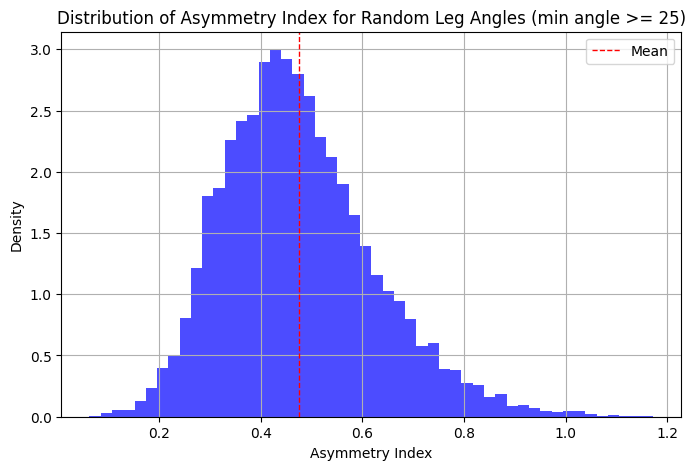

In [171]:
# Randomized asymmetry index range estimate with minimum angle constraint
rng = np.random.default_rng(0)
num_samples = 10000
num_legs = 6
min_angle = 25
def generate_valid_angles(num_samples, num_legs, min_angle):
    valid_angles = []
    while len(valid_angles) < num_samples:
        angles = rng.integers(0, 360, size=(num_samples, num_legs))
        for row in angles:
            sorted_row = np.sort(row)
            gaps = np.diff(sorted_row)
            wrap_gap = (sorted_row[0] + 360) - sorted_row[-1]
            all_gaps = np.append(gaps, wrap_gap)
            if np.all(all_gaps >= min_angle):
                valid_angles.append(row)
            else:
                # Regenerate this row until valid
                while True:
                    new_row = rng.integers(0, 360, size=(num_legs,))
                    sorted_new_row = np.sort(new_row)
                    gaps = np.diff(sorted_new_row)
                    wrap_gap = (sorted_new_row[0] + 360) - sorted_new_row[-1]
                    all_gaps = np.append(gaps, wrap_gap)
                    if np.all(all_gaps >= min_angle):
                        valid_angles.append(new_row)
                        break
    return np.array(valid_angles[:num_samples])

def asymmetry_index_from_array(angles_row):
    angles = np.mod(angles_row, 360)
    angles = np.sort(angles)
    gaps = np.diff(angles)
    wrap_gap = angles[0] + 360 - angles[-1]
    gaps = np.append(gaps, wrap_gap)
    mean_gap = np.mean(gaps)
    std_gap = np.std(gaps, ddof=0)
    return std_gap / mean_gap if mean_gap else 0.0

random_angles = generate_valid_angles(num_samples, num_legs, min_angle)
asym_values = np.array([asymmetry_index_from_array(row) for row in random_angles])

print('samples:', num_samples)
print('min:', asym_values.min())
print('max:', asym_values.max())
print('mean:', asym_values.mean())
print('median:', np.median(asym_values))
print('p5:', np.percentile(asym_values, 5))
print('p95:', np.percentile(asym_values, 95))

#plot distribution
plt.figure(figsize=(8, 5))
plt.hist(asym_values, bins=50, density=True, alpha=0.7, color='blue')
plt.title('Distribution of Asymmetry Index for Random Leg Angles (min angle >= 25)')
plt.xlabel('Asymmetry Index')
plt.ylabel('Density')
plt.grid(True)
plt.axvline(asym_values.mean(), color='red', linestyle='dashed', linewidth=1, label='Mean')
plt.legend()
plt.show()

In [14]:
unique_angles

,morphology_id,angle_0,angle_1,angle_2,angle_3,angle_4,angle_5,asymmetry_index
0,1,0,60,120,180,240,300,0.400366


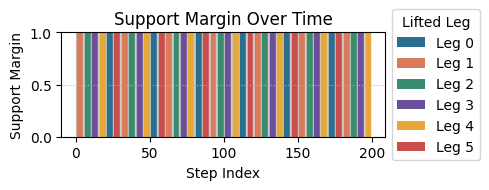

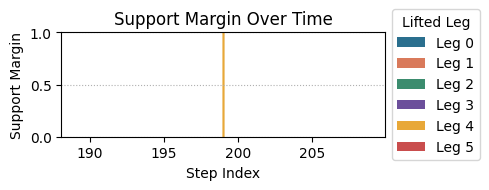

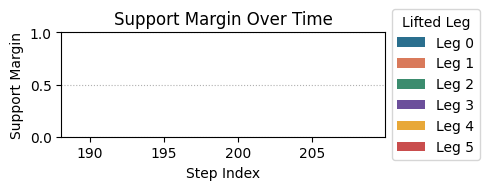

In [18]:
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
import pandas as pd

lifted_leg_counts = df['lifted_legs'].value_counts().sort_index()
colors = ['#2A6F8E', '#D97A5B', '#3B8C6E', '#6C4F9B', '#E8A838', '#C94D4D']

# Assuming 'colors' and 'df' are already defined
for sample_idx in df['sample_index'].unique():
    sample_data = df[df['sample_index'] == sample_idx]
    
    fig, ax1 = plt.subplots(figsize=(5, 2))

    # 1. Plot the support margin line first
    ax1.plot(
        sample_data['step_index'],
        sample_data['support_margin'],
        color="#000000",
        linewidth=2,
        zorder=2  # Ensures line is above the color blocks
    )

    # 2. Overlay the background colors for lifted legs
    # We use step_index to define the boundaries of each color block
    for i in range(len(sample_data) - 1):
        row = sample_data.iloc[i]
        next_row = sample_data.iloc[i+1]
        
        color = (
            colors[int(row['lifted_legs']) % len(colors)]
            if not pd.isna(row['lifted_legs'])
            else '#CCCCCC'
        )
        
        # Draw a vertical span from the current step to the next
        ax1.axvspan(
            row['step_index'], 
            next_row['step_index'], 
            color=color, 
            alpha=1, # Transparency so the grid and line are visible
            zorder = 1
        )
    ax1.set_title(f'Support Margin Over Time')
    ax1.set_ylabel('Support Margin')
    ax1.set_xlabel('Step Index')
    ax1.set_ylim(0.0, 1.0)
    ax1.grid(True, axis='y', linestyle=':', alpha=1)

    # 3. Integrated Legend
    leg_labels = [f'Leg {i}' for i in range(len(colors))]
    legend_handles = [Patch(facecolor=colors[i], alpha=1, label=leg_labels[i]) for i in range(len(colors))]
    
    # Place legend outside to the right
    ax1.legend(
        handles=legend_handles,
        loc='center left',
        bbox_to_anchor=(1, 0.5),
        title='Lifted Leg'
    )

    plt.tight_layout()
    plt.show()

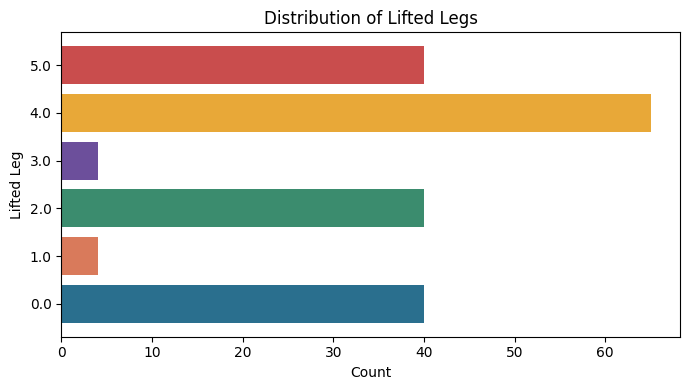

In [ ]:

plt.figure(figsize=(7, 4))
plt.barh(lifted_leg_counts.index.astype(str), lifted_leg_counts.values, 
         color=[colors[int(i) % len(colors)] for i in lifted_leg_counts.index if not pd.isna(i)])
plt.title('Distribution of Lifted Legs')
plt.xlabel('Count')
plt.ylabel('Lifted Leg')
plt.tight_layout()
plt.show()

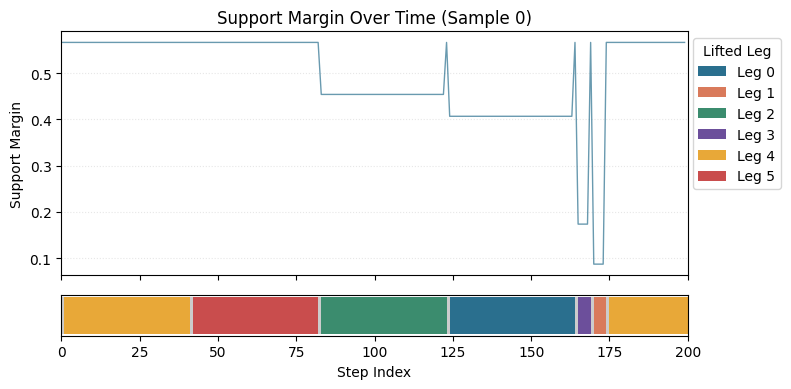

In [17]:
for sample_idx in df['sample_index'].unique():
    sample_data = df[df['sample_index'] == sample_idx]
    fig, (ax1, ax2) = plt.subplots(
        2, 1, figsize=(8, 4), gridspec_kw={'height_ratios': [6, 1]}, sharex=True
    )

    # Plot support margin as line
    ax1.plot(
        sample_data['step_index'],
        sample_data['support_margin'],
        color='#2A6F8E',
        linewidth=1,
        alpha=0.7,
    )
    ax1.set_title(f'Support Margin Over Time (Sample {sample_idx})')
    ax1.set_ylabel('Support Margin')
    ax1.grid(True, axis='y', linestyle=':', alpha=0.3)

    # Plot color bar for lifted legs
    for _, row in sample_data.iterrows():
        color = (
            colors[int(row['lifted_legs']) % len(colors)]
            if not pd.isna(row['lifted_legs'])
            else '#CCCCCC'
        )
        ax2.barh(0, 1, left=row['step_index'], color=color, edgecolor='none', height=0.3)

    ax2.set_xlim(sample_data['step_index'].min(), sample_data['step_index'].max() + 1)
    ax2.set_yticks([])
    ax2.set_xlabel('Step Index')

    # Create legend for legs
    from matplotlib.patches import Patch

    leg_labels = [f'Leg {i}' for i in range(len(colors))]
    legend_handles = [Patch(facecolor=colors[i], label=leg_labels[i]) for i in range(len(colors))]
    ax1.legend(
        handles=legend_handles,
        loc='upper right',
        bbox_to_anchor=(1.16, 1),
        title='Lifted Leg',
    )

    plt.tight_layout()
    plt.show()


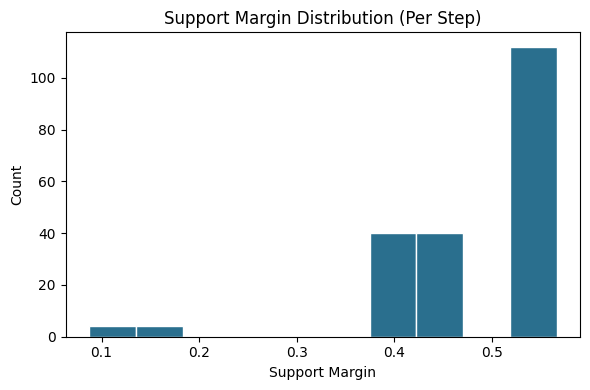

In [4]:
plt.figure(figsize=(6, 4))
plt.hist(df['support_margin'], bins=10, color='#2A6F8E', edgecolor='white')
plt.title('Support Margin Distribution (Per Step)')
plt.xlabel('Support Margin')
plt.ylabel('Count')
plt.tight_layout()
plt.show()


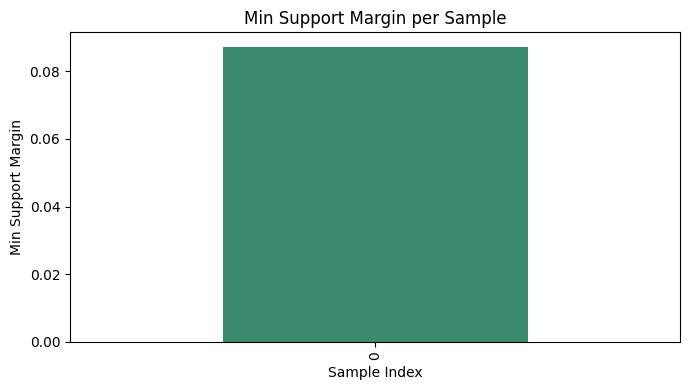

In [5]:
plt.figure(figsize=(7, 4))
df.groupby('sample_index')['support_margin'].min().plot(kind='bar', color='#3B8C6E')
plt.title('Min Support Margin per Sample')
plt.xlabel('Sample Index')
plt.ylabel('Min Support Margin')
plt.tight_layout()
plt.show()


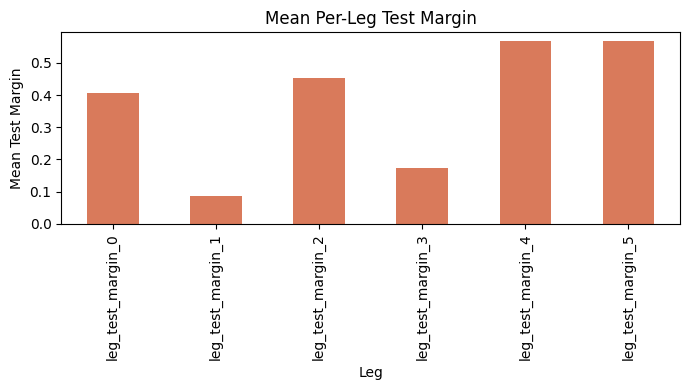

In [6]:
leg_cols = [c for c in df.columns if c.startswith('leg_test_margin_')]
plt.figure(figsize=(7, 4))
df[leg_cols].mean().plot(kind='bar', color='#D97A5B')
plt.title('Mean Per-Leg Test Margin')
plt.xlabel('Leg')
plt.ylabel('Mean Test Margin')
plt.tight_layout()
plt.show()


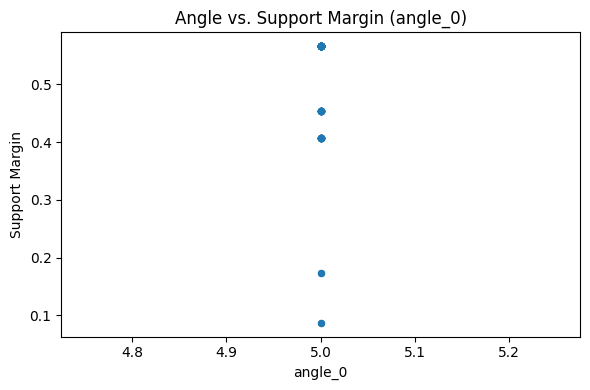

In [7]:
angle_cols = [c for c in df.columns if c.startswith('angle_')]
plt.figure(figsize=(6, 4))
plt.scatter(df[angle_cols[0]], df['support_margin'], s=18, alpha=0.6)
plt.title(f'Angle vs. Support Margin ({angle_cols[0]})')
plt.xlabel(angle_cols[0])
plt.ylabel('Support Margin')
plt.tight_layout()
plt.show()


# Angle Change Experiment
Visualize how symmetry changes over time and how it affects the signed stability margin.

In [10]:
import numpy as np

EXP_CSV_PATH = Path('data/stability_margin/angle_change_margin_20260115_150609.csv')
exp_df = pd.read_csv(EXP_CSV_PATH)
exp_df.head()


,global_step,phase_index,step_index,sim_time,angle_0,angle_1,angle_2,angle_3,angle_4,angle_5,support_margin,lifted_legs
0,0,0,0,0.01,16,30,168,210,283,316,0.358368,NaN
1,1,0,1,0.02,16,30,168,210,283,316,0.358368,0.0
2,2,0,2,0.03,16,30,168,210,283,316,0.358368,0.0
3,3,0,3,0.04,16,30,168,210,283,316,0.358368,0.0
4,4,0,4,0.05,16,30,168,210,283,316,0.358368,0.0


In [11]:
angle_cols = [c for c in exp_df.columns if c.startswith('angle_')]
angles = exp_df[angle_cols].to_numpy()

# Symmetry score: mean absolute deviation from ideal 60-degree spacing
sorted_angles = np.sort(angles, axis=1)
diffs = np.diff(np.hstack([sorted_angles, sorted_angles[:, :1] + 360]), axis=1)
symmetry_score = np.mean(np.abs(diffs - 60.0), axis=1)

exp_df = exp_df.copy()
exp_df['symmetry_score'] = symmetry_score
exp_df[['symmetry_score', 'support_margin']].head()


,symmetry_score,support_margin
0,30.333333,0.358368
1,30.333333,0.358368
2,30.333333,0.358368
3,30.333333,0.358368
4,30.333333,0.358368


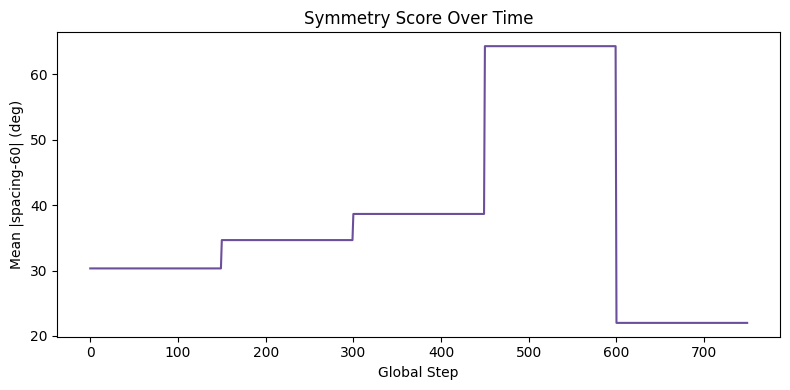

In [12]:
plt.figure(figsize=(8, 4))
plt.plot(exp_df['global_step'], exp_df['symmetry_score'], color='#6C4F9B', label='Symmetry score')
plt.title('Symmetry Score Over Time')
plt.xlabel('Global Step')
plt.ylabel('Mean |spacing-60| (deg)')
plt.tight_layout()
plt.show()


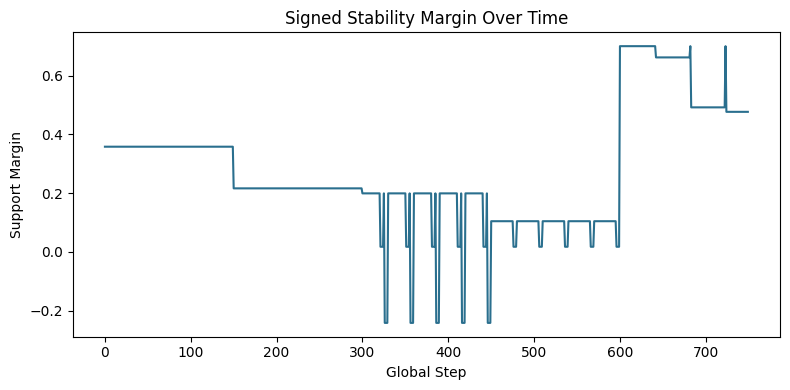

In [13]:
plt.figure(figsize=(8, 4))
plt.plot(exp_df['global_step'], exp_df['support_margin'], color='#2A6F8E', label='Support margin')
plt.title('Signed Stability Margin Over Time')
plt.xlabel('Global Step')
plt.ylabel('Support Margin')
plt.tight_layout()
plt.show()


In [ ]:
plt.figure(figsize=(6, 4))
plt.scatter(exp_df['symmetry_score'], exp_df['support_margin'], s=16, alpha=0.6)
plt.title('Symmetry vs. Signed Stability Margin')
plt.xlabel('Symmetry score (lower is more symmetric)')
plt.ylabel('Support Margin')
plt.tight_layout()
plt.show()
